In [63]:
from typing import TypedDict, Union, List, Annotated, Sequence
import operator
from langchain_core.messages import BaseMessage, ToolMessage, SystemMessage
from langgraph.graph.message import add_messages
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, AIMessage

from langgraph.graph import StateGraph, END
from langgraph.prebuilt import ToolNode
from langgraph.graph.message import add_messages
from langchain_core.tools import tool

In [64]:
class AgentState(TypedDict):
    """A dictionary representing the state of the agent."""
    messages: Annotated[List[BaseMessage], add_messages]

In [65]:
model = ChatGroq(model="openai/gpt-oss-120b",temperature=0)

In [66]:
@tool
def add(x : int , y : int) -> int:
    """Add two numbers."""
    return x + y

@tool
def subtract(x : int , y : int) -> int:
    """Subtract two numbers."""
    return x - y    

@tool
def multiply(x : int , y : int) -> int:
    """Multiply two numbers."""
    return x * y    

In [67]:
tools = [add, subtract, multiply]
model = model.bind_tools(tools)

In [68]:
def model_call(state: AgentState):
    response = model.invoke(
        [
            SystemMessage(
content=(
                    "You are a helpful assistant. For every arithmetic calculation, "
                    "use the appropriate provided tool (add, subtract, or multiply); "
                    "do not calculate the result yourself. For calculations with "
                    "dependent steps, call one tool at a time and use its result in "
                    "the next step. For requests that do not need arithmetic, answer "
                    "directly without a tool."
                )
            ),
            *state["messages"],
        ]
    )
    return {"messages": [response]}

In [69]:
def should_continue_or_not(state : AgentState) :
    """Determine whether the agent should continue or stop."""
    messages = state["messages"]    
    if not messages[-1].tool_calls:
        print(f"-----\nNo Tool calls")
        return "end"
    print(f"-----\nTool calls: {messages[-1].tool_calls}")
    return "continue"
    

In [70]:
graph = StateGraph(AgentState)

graph.add_node("tools",ToolNode(tools = tools))
graph.add_node("agent",model_call)

graph.set_entry_point("agent")
graph.add_conditional_edges(
    "agent",
    should_continue_or_not,
    {
        "continue": "tools",
        "end": END  
    }
)
graph.add_edge("tools","agent")

app = graph.compile()

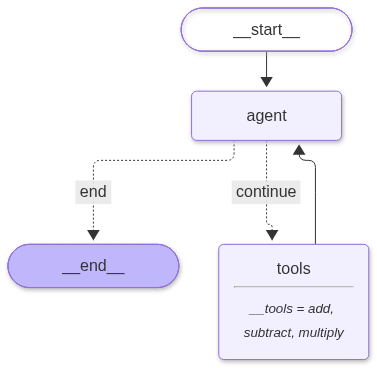

In [71]:
app

In [72]:
res = app.invoke({
    "messages":[
        HumanMessage(content="What is your name?"),
    ]
})

-----
No Tool calls


In [73]:
for i in res['messages']:
    print(i.__class__.__name__ + " : " +i.content)

HumanMessage : What is your name?
AIMessage : I’m ChatGPT, your helpful AI assistant.
